# Stack Overflow в 2008 году. Публикации, авторы и просмотры

Учебный проект Яндекс Практикума · PostgreSQL

С сентября по декабрь число вопросов и ответов сократилось с **70 371 до 44 592**. Я разобрал, в каком месяце спад был сильнее всего, как менялась активность сентябрьских авторов и какие публикации накопили больше просмотров.

[Знаки признания и первые публикации](#practice) · [Активность авторов и аудитории](#analysis) · [Выводы](#findings)

## Как устроены данные

Вопрос и ответ — отдельные строки `posts`. Автор связан с постом по `user_id`, а ответ с исходным вопросом — по `parent_id`. Оценка поста хранится в `score`, просмотры поста — в `views_count`, просмотры профиля — в `users.views`. Эти три показателя отвечают на разные вопросы.

Для анализа публикаций беру 2008 год. Голоса и значки могут относиться к более поздним датам. Ограничиваю их период там, где этого требует вопрос.

<!-- Схема учебной базы: 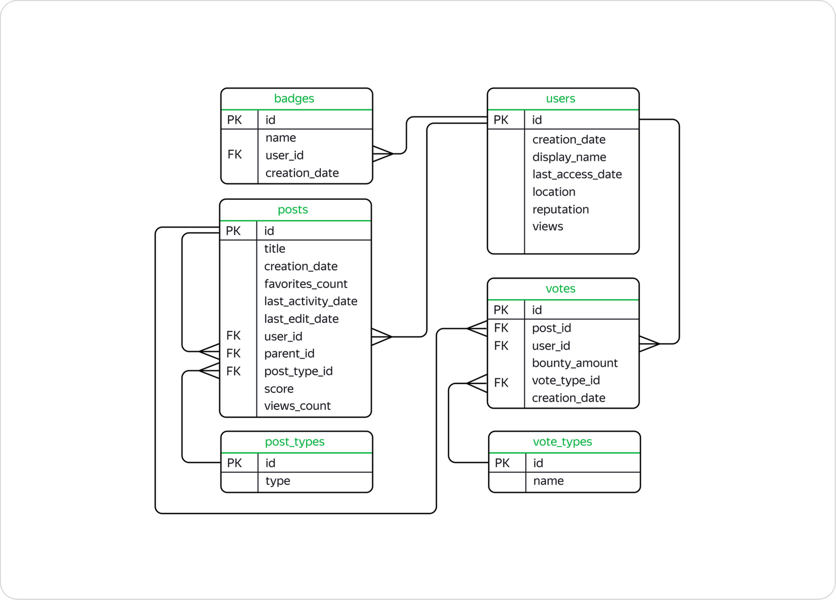 -->

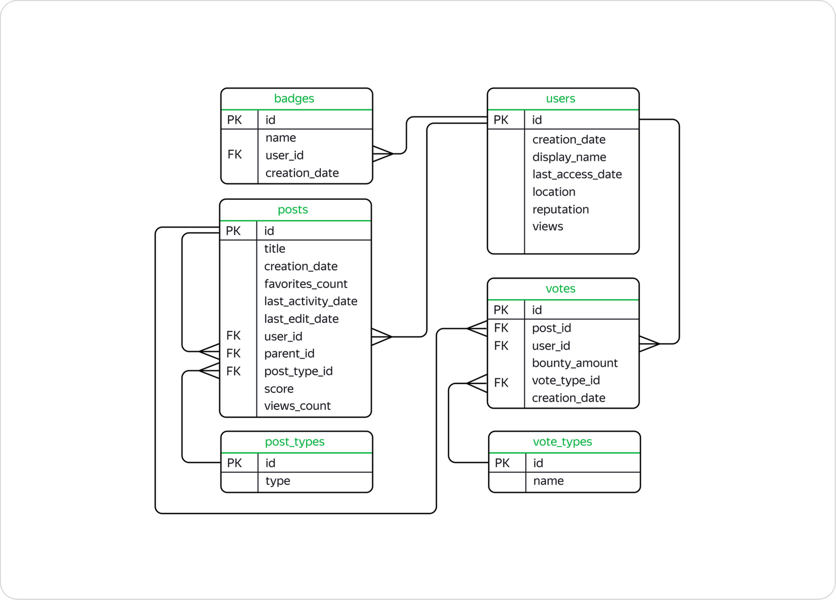

In [1]:
from base64 import b64decode
import json
from pathlib import Path

from IPython.display import Image, display


def embedded_schema():
    # При запуске Jupyter читает рисунок из вложения в файле этого ноутбука.
    for notebook in Path.cwd().glob('*.ipynb'):
        with notebook.open(encoding='utf-8-sig') as file:
            cells = json.load(file)['cells']
        for cell in cells[:3]:
            schema = cell.get('attachments', {}).get('stackoverflow-schema.png')
            if schema:
                return b64decode(schema['image/png'])
    raise FileNotFoundError('Откройте ноутбук в Jupyter из папки с его файлом.')


display(Image(data=embedded_schema(), alt='Связи шести таблиц учебной базы Stack Overflow'))

### Как читать и пересчитать работу

В режиме просмотра таблицы и графики используют сохранённые числовые сводки учебной выборки. Для пересчёта всех 20 запросов в Jupyter задайте строку подключения к PostgreSQL в переменной окружения `STACKOVERFLOW_DSN`. Нужны схема `stackoverflow`, Python, pandas, Matplotlib и, для подключения, `psycopg` версии 3. Каждая ячейка `%%postgres` содержит самостоятельный SQL-запрос. При подключении сводки для анализа выводятся полностью, для детальных выборок показываются первые десять строк.

In [2]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.core.magic import register_cell_magic
from IPython.display import display

dsn = os.getenv('STACKOVERFLOW_DSN')
connection = None
results = {}
# Полные сводки для таблиц и графиков.
summary_queries = {14, 16, 18, 19, 20}
if dsn:
    import psycopg
    connection = psycopg.connect(dsn, autocommit=True)
    connection.read_only = True

@register_cell_magic
def postgres(line, sql):
    number = int(line.strip())
    if connection is None:
        return
    with connection.cursor() as cursor:
        cursor.execute(sql)
        columns = [column.name for column in cursor.description]
        rows = cursor.fetchall() if number in summary_queries else cursor.fetchmany(10)
    frame = pd.DataFrame.from_records(rows, columns=columns)
    if number in summary_queries:
        results[number] = frame
    else:
        display(frame)

plt.rcParams.update({
    'figure.dpi': 105, 'font.size': 10, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.axisbelow': True, 'axes.edgecolor': '#9babaf',
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
})
print('Источник сводок —', 'подключённая база PostgreSQL' if connection else 'сохранённые агрегаты учебной выборки')

Источник сводок — сохранённые агрегаты учебной выборки


<a id="practice"></a>
## Часть I. Знаки признания и первые публикации

Начну с разных единиц подсчёта. У одного поста бывает несколько голосов, а один пользователь может получить несколько значков за день. При соединении таблиц важно сохранить именно ту единицу, о которой задан вопрос.

### 01. Популярные вопросы

Посчитать вопросы, которые набрали больше 300 очков или попали в закладки хотя бы 100 раз.

In [3]:
%%postgres 1
SELECT COUNT(*) AS question_count
FROM stackoverflow.posts AS p
JOIN stackoverflow.post_types AS pt ON pt.id = p.post_type_id
WHERE pt.type = 'Question'
  AND (p.score > 300 OR p.favorites_count >= 100);

Условию соответствует **1 355 вопросов**. Высокая оценка и попадание в закладки — два разных способа попасть в эту группу.

### 02. Среднее число вопросов в день

Найти среднее число вопросов за день с 1 по 18 ноября 2008 года включительно и округлить до целого.

In [4]:
%%postgres 2
SELECT ROUND(COUNT(*)::numeric / 18) AS avg_questions_per_day
FROM stackoverflow.posts AS p
JOIN stackoverflow.post_types AS pt ON pt.id = p.post_type_id
WHERE pt.type = 'Question'
  AND p.creation_date >= DATE '2008-11-01'
  AND p.creation_date < DATE '2008-11-19';

С 1 по 18 ноября площадка получала в среднем **383 вопроса в день**. Это частота публикации вопросов за указанные 18 дней.

### 03. Значок в день регистрации

Посчитать уникальных пользователей, которые получили хотя бы один значок в день регистрации.

In [5]:
%%postgres 3
SELECT COUNT(*) AS user_count
FROM stackoverflow.users AS u
WHERE EXISTS (
    SELECT 1
    FROM stackoverflow.badges AS b
    WHERE b.user_id = u.id
      AND b.creation_date::date = u.creation_date::date
);

**7 047 пользователей** получили хотя бы один значок в день регистрации. Чтобы оценить долю таких новичков, потребовался бы также знаменатель — число зарегистрированных пользователей.

### 04. Голоса за посты Joel Coehoorn

Посчитать уникальные посты автора с именем Joel Coehoorn, которые получили хотя бы один голос.

In [6]:
%%postgres 4
SELECT COUNT(*) AS voted_post_count
FROM stackoverflow.posts AS p
JOIN stackoverflow.users AS u ON u.id = p.user_id
WHERE u.display_name = 'Joel Coehoorn'
  AND EXISTS (
      SELECT 1
      FROM stackoverflow.votes AS v
      WHERE v.post_id = p.id
  );

Хотя бы один голос получили **12 разных публикаций** Joel Coehoorn. Повторные голоса за один пост не увеличивают это число.

### 05. Обратная нумерация типов голосов

Вывести все поля справочника типов голосов и добавить столбец rank с обратной нумерацией. Отсортировать строки по возрастанию id.

In [7]:
%%postgres 5
SELECT
    vt.*,
    ROW_NUMBER() OVER (ORDER BY vt.id DESC) AS rank
FROM stackoverflow.vote_types AS vt
ORDER BY vt.id;

В справочнике типу с идентификатором 1 соответствует обратный номер 15, типу с идентификатором 2 — номер 14.

### 06. Кто чаще голосовал за закрытие

Вывести id и число голосов Close для десяти пользователей, которые чаще всего голосовали за закрытие. Упорядочить результат по убыванию числа голосов, а при равенстве — по убыванию id.

In [8]:
%%postgres 6
SELECT
    v.user_id,
    COUNT(*) AS close_votes
FROM stackoverflow.votes AS v
JOIN stackoverflow.vote_types AS vt ON vt.id = v.vote_type_id
WHERE vt.name = 'Close'
  AND v.user_id IS NOT NULL
GROUP BY v.user_id
ORDER BY close_votes DESC, v.user_id DESC
LIMIT 10;

Первое место по числу голосов за закрытие разделили пользователи 20646 и 14728 — по **36 голосов**. Третий результат — 29.

### 07. Лидеры по числу значков

Для десяти пользователей с наибольшим числом значков с 15 ноября по 15 декабря 2008 года включительно вывести id, число значков и место. При равенстве числа значков присвоить одно место и расположить пользователей по возрастанию id.

In [9]:
%%postgres 7
WITH badge_counts AS (
    SELECT user_id, COUNT(*) AS badge_count
    FROM stackoverflow.badges
    WHERE creation_date >= DATE '2008-11-15'
      AND creation_date < DATE '2008-12-16'
      AND user_id IS NOT NULL
    GROUP BY user_id
)
SELECT
    user_id,
    badge_count,
    DENSE_RANK() OVER (ORDER BY badge_count DESC) AS badge_rank
FROM badge_counts
ORDER BY badge_count DESC, user_id
LIMIT 10;

Лидер получил **149 значков** за период, второй участник — 45. У двух участников по 28 значков, поэтому у них одинаковое шестое место.

### 08. Очки поста и среднее автора

Для каждого поста с заголовком и ненулевой оценкой вывести заголовок, id автора, оценку поста и среднюю оценку подходящих постов автора, округлённую до целого.

In [10]:
%%postgres 8
SELECT
    p.title,
    p.user_id,
    p.score,
    ROUND(AVG(p.score) OVER (PARTITION BY p.user_id)) AS avg_author_score
FROM stackoverflow.posts AS p
WHERE NULLIF(TRIM(p.title), '') IS NOT NULL
  AND p.score <> 0
  AND p.user_id IS NOT NULL
ORDER BY p.user_id, p.id;

Например, у автора с идентификатором 1 округлённое среднее по отобранным постам — 573 очка. Это среднее по публикациям с заголовком и ненулевой оценкой.

### 09. Посты авторов с более чем тысячей значков

Вывести заголовки постов тех пользователей, которые получили больше 1 000 значков. Пропустить публикации без заголовка.

In [11]:
%%postgres 9
WITH prolific_badge_owners AS (
    SELECT user_id
    FROM stackoverflow.badges
    GROUP BY user_id
    HAVING COUNT(*) > 1000
)
SELECT p.title
FROM stackoverflow.posts AS p
JOIN prolific_badge_owners AS b ON b.user_id = p.user_id
WHERE NULLIF(TRIM(p.title), '') IS NOT NULL
ORDER BY p.id;

Порог относится к числу наград автора за весь доступный период. После отбора авторов вывожу по одной строке на каждый их пост с заголовком.

### 10. Просмотры профилей пользователей из США

Разбить пользователей из США с положительным числом просмотров профиля на три группы. Группа 1 начинается с 350 просмотров, группа 2 охватывает 100–349, группа 3 — 1–99. Вывести id, число просмотров и группу.

In [12]:
%%postgres 10
SELECT
    id AS user_id,
    views,
    CASE
        WHEN views >= 350 THEN 1
        WHEN views >= 100 THEN 2
        ELSE 3
    END AS view_group
FROM stackoverflow.users
WHERE location ILIKE '%United States%'
  AND views > 0
ORDER BY id;

Например, профиль с 174 просмотрами попадает во вторую группу, а профиль с 1 079 — в первую. В обеих строках речь идёт о просмотрах профиля пользователя.

### 11. Лидеры трёх групп по просмотрам

Для тех же групп пользователей из США вывести id, группу и число просмотров у всех лидеров каждой группы. Отсортировать по убыванию просмотров, затем по возрастанию id.

In [13]:
%%postgres 11
WITH profile_groups AS (
    SELECT
        id AS user_id,
        views,
        CASE
            WHEN views >= 350 THEN 1
            WHEN views >= 100 THEN 2
            ELSE 3
        END AS view_group
    FROM stackoverflow.users
    WHERE location ILIKE '%United States%'
      AND views > 0
),
group_maxima AS (
    SELECT
        user_id,
        view_group,
        views,
        MAX(views) OVER (PARTITION BY view_group) AS max_views
    FROM profile_groups
)
SELECT user_id, view_group, views
FROM group_maxima
WHERE views = max_views
ORDER BY views DESC, user_id;

Максимум в первой группе — **21 991 просмотр**, во второй — 349, в третьей — 99. В третьей группе порога достигли несколько профилей, и все они входят в результат.

### 12. Регистрации в ноябре по дням

Для каждого дня ноября 2008 года вывести номер дня, число регистраций и накопительное число регистраций с начала месяца.

In [14]:
%%postgres 12
WITH daily_registrations AS (
    SELECT
        EXTRACT(DAY FROM creation_date)::integer AS day_number,
        COUNT(*) AS registrations
    FROM stackoverflow.users
    WHERE creation_date >= DATE '2008-11-01'
      AND creation_date < DATE '2008-12-01'
    GROUP BY EXTRACT(DAY FROM creation_date)::integer
),
november AS (
    SELECT
        calendar.day_number,
        COALESCE(d.registrations, 0) AS registrations
    FROM generate_series(1, 30) AS calendar(day_number)
    LEFT JOIN daily_registrations AS d USING (day_number)
)
SELECT
    day_number,
    registrations,
    SUM(registrations) OVER (
        ORDER BY day_number ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS cumulative_registrations
FROM november
ORDER BY day_number;

1 ноября зарегистрировались 34 пользователя, 2 ноября — ещё 48. К концу 2 ноября накопительный итог равен 82, а к концу 5 ноября — 471.

### 13. Время до первого поста

Для каждого пользователя с публикациями вывести id и интервал между регистрацией и созданием его первого поста.

In [15]:
%%postgres 13
SELECT
    u.id AS user_id,
    MIN(p.creation_date) - u.creation_date AS time_to_first_post
FROM stackoverflow.users AS u
JOIN stackoverflow.posts AS p ON p.user_id = u.id
GROUP BY u.id, u.creation_date
ORDER BY u.id;

Интервал сохраняет точность до секунды. Например, у пользователя 7160 между регистрацией и первым постом прошло 9 минут 46 секунд.

<a id="analysis"></a>
## Часть II. Активность авторов и аудитории

Сначала сравню внимание к публикациям разных месяцев, затем выделю когорту авторов и сопоставлю её с динамикой всех постов.

### 14. Просмотры постов по месяцу публикации

Для каждого месяца 2008 года, в котором были публикации, посчитать сумму просмотров постов. Вывести месяцы по убыванию этой суммы.

In [16]:
%%postgres 14
SELECT
    DATE_TRUNC('month', p.creation_date)::date AS month_start,
    SUM(p.views_count) AS total_views
FROM stackoverflow.posts AS p
WHERE p.creation_date >= DATE '2008-01-01'
  AND p.creation_date < DATE '2009-01-01'
GROUP BY month_start
ORDER BY total_views DESC NULLS LAST, month_start;

Месяц определяю по дате создания поста. Счётчик показывает, сколько просмотров набрали публикации этого месяца. Дат отдельных просмотров в таблице нет.

,Месяц публикации,Просмотры
0,2008-09,452928568
1,2008-10,365400138
2,2008-11,221759651
3,2008-12,197792841
4,2008-08,131367083
5,2008-07,669895


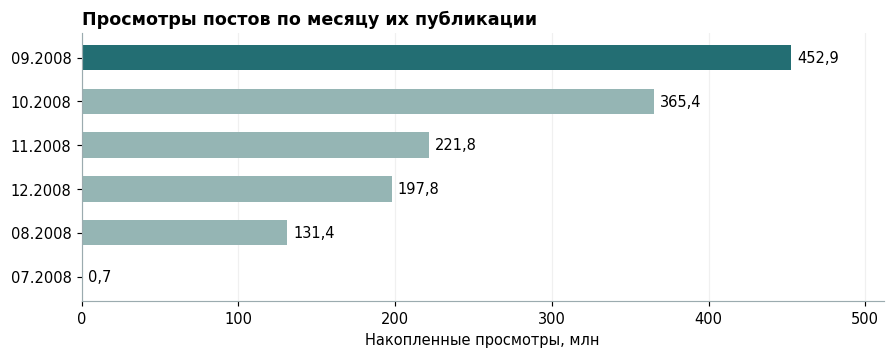

In [17]:
views = results.get(14, pd.DataFrame({
    'month_start': ['2008-09-01', '2008-10-01', '2008-11-01',
                    '2008-12-01', '2008-08-01', '2008-07-01'],
    'total_views': [452928568, 365400138, 221759651, 197792841, 131367083, 669895],
})).copy()
views['month_start'] = pd.to_datetime(views['month_start'])
views['total_views'] = pd.to_numeric(views['total_views'])
display(views.assign(month_start=views['month_start'].dt.strftime('%Y-%m'))
        .rename(columns={'month_start': 'Месяц публикации', 'total_views': 'Просмотры'}))
ranked = views.sort_values('total_views')
labels = ranked['month_start'].dt.strftime('%m.%Y')
fig, ax = plt.subplots(figsize=(8.4, 3.3), layout='constrained')
amounts = ranked['total_views'] / 1_000_000
bars = ax.barh(labels, amounts, height=.58,
               color=['#236e73' if n == amounts.max() else '#95b5b4' for n in amounts])
ax.bar_label(bars, labels=[f'{n:.1f}'.replace('.', ',') for n in amounts], padding=4)
ax.set(title='Просмотры постов по месяцу их публикации', xlabel='Накопленные просмотры, млн',
       xlim=(0, amounts.max() * 1.13))
ax.grid(axis='x', alpha=.18)
plt.show()

Наибольший суммарный счётчик у постов, созданных в сентябре, — **452,9 млн просмотров**. У октябрьских публикаций — 365,4 млн. По этим значениям нельзя определить, сколько людей зашло на сайт в сентябре или октябре. Просмотр мог произойти позже, а один человек мог посмотреть несколько постов.

### 15. Активные авторы ответов после регистрации

Найти пользователей, которые дали больше 100 ответов за первый месяц после регистрации, включая день регистрации. Для каждого имени вывести число подходящих аккаунтов и отсортировать имена по алфавиту.

In [18]:
%%postgres 15
WITH active_authors AS (
    SELECT u.id, u.display_name
    FROM stackoverflow.users AS u
    JOIN stackoverflow.posts AS p ON p.user_id = u.id
    JOIN stackoverflow.post_types AS pt ON pt.id = p.post_type_id
    WHERE pt.type = 'Answer'
      AND p.creation_date >= u.creation_date
      AND p.creation_date < u.creation_date::date + INTERVAL '1 month'
    GROUP BY u.id, u.display_name
    HAVING COUNT(*) > 100
)
SELECT
    display_name,
    COUNT(DISTINCT id) AS user_count
FROM active_authors
GROUP BY display_name
ORDER BY display_name;

Считаю по календарным датам. Для регистрации 1 сентября окно открывается в момент регистрации и закрывается перед 1 октября. Порог проверяю по каждому аккаунту до объединения одинаковых имён.

Порог в 100 ответов проверяю **до** группировки имён. Если у двух тёзок по 60 ответов, вместе у них 120, но ни один не проходит отбор. Это особенно важно для часто встречающихся имён.

### 16. Публикации сентябрьской когорты

Посчитать по месяцам посты за 2008 год у пользователей, которые зарегистрировались в сентябре и опубликовали хотя бы один пост в декабре. Вывести месяцы от поздних к ранним.

In [19]:
%%postgres 16
WITH cohort AS (
    SELECT u.id
    FROM stackoverflow.users AS u
    WHERE u.creation_date >= DATE '2008-09-01'
      AND u.creation_date < DATE '2008-10-01'
      AND EXISTS (
          SELECT 1
          FROM stackoverflow.posts AS december_post
          WHERE december_post.user_id = u.id
            AND december_post.creation_date >= DATE '2008-12-01'
            AND december_post.creation_date < DATE '2009-01-01'
      )
)
SELECT
    COUNT(*) AS post_count,
    DATE_TRUNC('month', p.creation_date)::date AS month_start
FROM stackoverflow.posts AS p
JOIN cohort AS c ON c.id = p.user_id
WHERE p.creation_date >= DATE '2008-01-01'
  AND p.creation_date < DATE '2009-01-01'
GROUP BY month_start
ORDER BY month_start DESC;

Декабрьская публикация определяет, попадёт ли пользователь в когорту. Для отобранных авторов считаю все публикации за год. Несколько декабрьских постов одного автора не дублируют его остальные записи.

In [20]:
cohort = results.get(16, pd.DataFrame({
    'post_count': [17641, 18294, 27171, 24870, 32],
    'month_start': pd.to_datetime(['2008-12-01', '2008-11-01', '2008-10-01',
                                   '2008-09-01', '2008-08-01']),
})).copy()
cohort['month_start'] = pd.to_datetime(cohort['month_start'])
display(cohort[['month_start', 'post_count']].assign(
    month_start=cohort['month_start'].dt.strftime('%Y-%m')
).rename(columns={'month_start': 'Месяц публикации', 'post_count': 'Посты когорты'}))

,Месяц публикации,Посты когорты
0,2008-12,17641
1,2008-11,18294
2,2008-10,27171
3,2008-09,24870
4,2008-08,32


Из выбранных авторов больше всего постов в октябре — **27 171**. У этой же группы есть 32 августовских поста, хотя месяц регистрации — сентябрь. Я сохранил их в годовой сводке и отдельно отметил расхождение дат. При расчёте активности после регистрации эти строки потребовали бы отдельного отбора.

### 17. Просмотры постов автора нарастающим итогом

Для каждого поста вывести идентификатор автора, время публикации, просмотры поста и накопленную сумму просмотров его публикаций. Отсортировать строки по автору и времени создания.

In [21]:
%%postgres 17
SELECT
    p.user_id,
    p.creation_date,
    p.views_count,
    SUM(p.views_count) OVER (
        PARTITION BY p.user_id
        ORDER BY p.creation_date, p.id
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS cumulative_views
FROM stackoverflow.posts AS p
WHERE p.user_id IS NOT NULL
ORDER BY p.user_id, p.creation_date, p.id;

У автора с идентификатором 1 первые две публикации набрали 480 476 и 136 033 просмотра. Накопительный итог после второй — **616 509**. Следующая публикация с нулём просмотров оставляет его прежним.

### 18. Среднее число дней с публикациями

За период с 1 по 7 декабря 2008 года включительно найти среднее число дней с публикациями на одного активного автора. Округлить результат до целого числа.

In [22]:
%%postgres 18
WITH author_activity AS (
    SELECT
        p.user_id,
        COUNT(DISTINCT p.creation_date::date) AS active_days
    FROM stackoverflow.posts AS p
    WHERE p.creation_date >= DATE '2008-12-01'
      AND p.creation_date < DATE '2008-12-08'
      AND p.user_id IS NOT NULL
    GROUP BY p.user_id
)
SELECT ROUND(AVG(active_days))::integer AS avg_active_days
FROM author_activity;

Каждый день с публикацией учитываю один раз для каждого автора. В знаменатель входят пользователи, которые опубликовали хотя бы один пост в эту неделю.

In [23]:
activity = results.get(18, pd.DataFrame({'avg_active_days': [2]}))
print('Дней с публикациями в среднем, после округления:', int(activity.iloc[0, 0]))

Дней с публикациями в среднем, после округления: 2


Среди авторов, которые что-либо опубликовали 1–7 декабря, на человека приходилось в среднем **два дня с публикациями** после округления. Чтение постов и посещения без публикаций в этот показатель не входят.

### 19. Изменение числа публикаций с сентября по декабрь

Для каждого месяца с сентября по декабрь 2008 года вывести его номер, число постов и процент изменения к предыдущему месяцу. Округлить процент до двух знаков после запятой.

In [24]:
%%postgres 19
WITH months AS (
    SELECT month_start
    FROM GENERATE_SERIES(
        TIMESTAMP '2008-09-01', TIMESTAMP '2008-12-01', INTERVAL '1 month'
    ) AS calendar(month_start)
),
monthly_counts AS (
    SELECT m.month_start, COUNT(p.id) AS post_count
    FROM months AS m
    LEFT JOIN stackoverflow.posts AS p
        ON p.creation_date >= m.month_start
       AND p.creation_date < m.month_start + INTERVAL '1 month'
    GROUP BY m.month_start
),
monthly_comparison AS (
    SELECT
        month_start,
        post_count,
        LAG(post_count) OVER (ORDER BY month_start) AS previous_count
    FROM monthly_counts
)
SELECT
    EXTRACT(MONTH FROM month_start)::integer AS month_number,
    post_count,
    ROUND(100.0 * (post_count - previous_count) / NULLIF(previous_count, 0), 2) AS change_pct
FROM monthly_comparison
ORDER BY month_start;

Для сентября изменение равно NULL, поскольку сравнение начинается внутри выбранного периода. Месяц без постов получает ноль. Если в предыдущем месяце было ноль постов, процент изменения не определён.

In [25]:
monthly = results.get(19, pd.DataFrame({
    'month_number': [9, 10, 11, 12], 'post_count': [70371, 63102, 46975, 44592],
})).copy()
monthly = monthly[['month_number', 'post_count']].sort_values('month_number').reset_index(drop=True)
monthly['change_pct'] = monthly['post_count'].pct_change().mul(100).round(2)
monthly['date'] = pd.to_datetime(dict(year=2008, month=monthly['month_number'], day=1))
monthly['per_day'] = monthly['post_count'] / monthly['date'].dt.days_in_month
display(monthly[['month_number', 'post_count', 'change_pct', 'per_day']]
        .rename(columns={'month_number': 'Месяц', 'post_count': 'Посты',
                         'change_pct': 'Изменение, %', 'per_day': 'Постов в день'})
        .style.format({'Изменение, %': '{:.2f}', 'Постов в день': '{:,.0f}'}, na_rep='—'))

,Месяц,Посты,"Изменение, %",Постов в день
0,9,70371,—,"2,346"
1,10,63102,-10.33,"2,036"
2,11,46975,-25.56,"1,566"
3,12,44592,-5.07,"1,438"


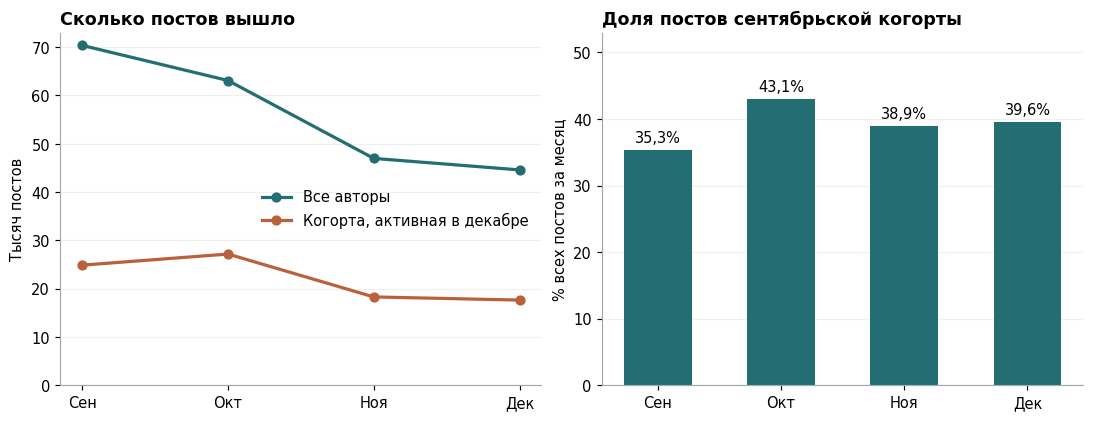

In [26]:
cohort_by_month = cohort.assign(month_number=cohort['month_start'].dt.month).set_index('month_number')
comparison = monthly.join(cohort_by_month['post_count'].rename('cohort_posts'), on='month_number')
comparison['cohort_posts'] = comparison['cohort_posts'].fillna(0)
comparison['share_pct'] = 100 * comparison['cohort_posts'] / comparison['post_count'].where(comparison['post_count'] > 0)
labels = ['Сен', 'Окт', 'Ноя', 'Дек']
fig, (left, right) = plt.subplots(1, 2, figsize=(10.3, 3.9), layout='constrained')
for field, color, name in [('post_count', '#236e73', 'Все авторы'),
                           ('cohort_posts', '#ba613b', 'Когорта, активная в декабре')]:
    left.plot(labels, comparison[field] / 1000, marker='o', color=color, lw=2.2, label=name)
left.set(title='Сколько постов вышло', ylabel='Тысяч постов', ylim=(0, None))
left.legend(frameon=False, loc='center right')
bars = right.bar(labels, comparison['share_pct'], color='#236e73', width=0.55)
right.bar_label(bars, labels=[f'{v:.1f}%'.replace('.', ',') for v in comparison['share_pct']],
                padding=3)
right.set(title='Доля постов сентябрьской когорты', ylabel='% всех постов за месяц',
          ylim=(0, comparison['share_pct'].max() * 1.23))
for ax in (left, right):
    ax.grid(axis='y', alpha=0.18)
plt.show()

Самый резкий спад пришёлся на ноябрь — **−25,56%** к октябрю. Разница сохраняется и после поправки на длину месяца. В октябре в день выходило в среднем 2 036 постов, в ноябре — 1 566. В октябре сентябрьская когорта дала 43,1% всех публикаций. Это вклад группы, отобранной по декабрьской активности, поэтому её долю нельзя интерпретировать как удержание всех сентябрьских новичков.

### 20. Последний пост недели у самого активного автора

Найти пользователя с наибольшим числом постов за всё время. Для каждой недели, когда он публиковался в октябре 2008 года, вывести номер недели и дату со временем его последнего октябрьского поста за эту неделю.

In [27]:
%%postgres 20
WITH top_author AS (
    SELECT p.user_id
    FROM stackoverflow.posts AS p
    WHERE p.user_id IS NOT NULL
    GROUP BY p.user_id
    ORDER BY COUNT(*) DESC, p.user_id
    LIMIT 1
)
SELECT
    EXTRACT(WEEK FROM p.creation_date)::integer AS week_number,
    MAX(p.creation_date) AS last_post_at
FROM stackoverflow.posts AS p
JOIN top_author AS a ON a.user_id = p.user_id
WHERE p.creation_date >= DATE '2008-10-01'
  AND p.creation_date < DATE '2008-11-01'
GROUP BY week_number
ORDER BY week_number;

Самый активный автор публиковался в каждой из пяти календарных недель, на которые пришёлся октябрь. Для последней недели учитываю только записи по 31 октября включительно.

In [28]:
weekly = results.get(20, pd.DataFrame({
    'week_number': [40, 41, 42, 43, 44],
    'last_post_at': pd.to_datetime(['2008-10-05 09:00:58', '2008-10-12 21:22:23',
                                    '2008-10-19 06:49:30', '2008-10-26 21:44:36',
                                    '2008-10-31 22:16:01']),
}))
display(weekly.rename(columns={'week_number': 'Неделя ISO',
                               'last_post_at': 'Последняя публикация в октябре'}))

,Неделя ISO,Последняя публикация в октябре
0,40,2008-10-05 09:00:58
1,41,2008-10-12 21:22:23
2,42,2008-10-19 06:49:30
3,43,2008-10-26 21:44:36
4,44,2008-10-31 22:16:01


<a id="findings"></a>
## Выводы

- **Публиковать стали реже.** В декабре вышло на 25 779 постов меньше, чем в сентябре, — падение на 36,63%. Разница в числе дней сама по себе спад не объясняет. Для проверки причин я бы отдельно сравнил число активных авторов и число публикаций на автора.
- **Максимум внимания получили сентябрьские публикации.** Их суммарный счётчик — 452,9 млн просмотров. Чтобы оценить именно посещаемость по месяцам, понадобились бы даты самих просмотров.
- **Сентябрьская когорта внесла заметный вклад.** Авторы, зарегистрированные в сентябре и активные в декабре, дали 27 171 пост в октябре и 17 641 в декабре. Изменение объёма публикаций этой группы и возвращаемость пользователей — разные показатели.

In [29]:
if connection is not None:
    connection.close()